Tabular Baseline R^2 Score:         0.908
Tabular Engineered Physics R^2 Score: 0.799


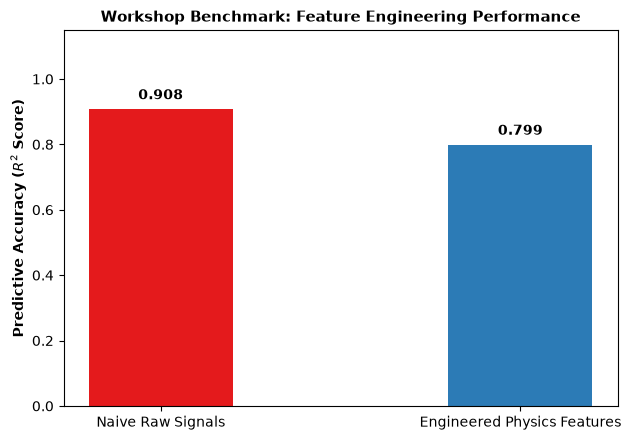

c:\Users\hp\OneDrive - University of Southampton\Year 3\2 DCE\DCE Code\.venv\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but DecisionTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\hp\OneDrive - University of Southampton\Year 3\2 DCE\DCE Code\.venv\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but DecisionTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\hp\OneDrive - University of Southampton\Year 3\2 DCE\DCE Code\.venv\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but DecisionTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\hp\OneDrive - University of Southampton\Year 3\2 DCE\DCE Code\.venv\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but DecisionTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\hp\OneDrive - University of Southam

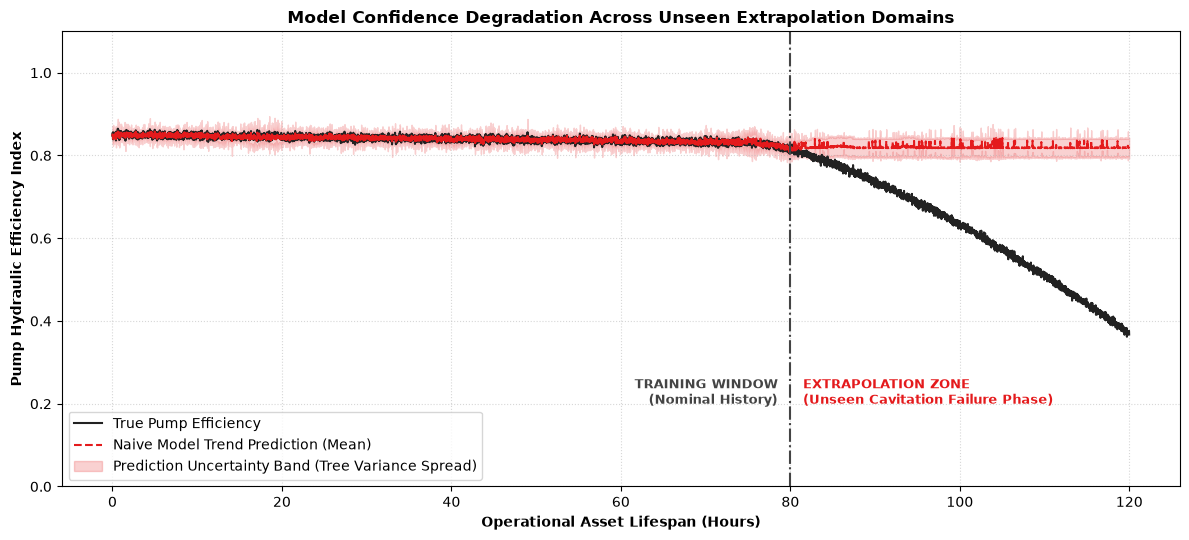

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split

# --- STEP 1: LOAD TELEMETRY & FILTER DROPOUTS ---
working_df = pd.read_csv("../pump_telemetry3.csv", parse_dates=["timestamp"])
clean_df = working_df.copy()

# Fix real field dropout frames using standard industrial forward fill
target_channels = ["raw_vibration", "drifted_pressure", "motor_temp"]
clean_df[target_channels] = clean_df[target_channels].ffill().bfill()

raw_features = ["raw_vibration", "drifted_pressure", "motor_temp"]
engineered_features = ["vibration_rms", "vibration_trend", "pressure_reserve", "motor_temp"]

# --- STEP 2: EMBEDDED INLINE FEATURE ENGINEERING ---
# 1. Extract moving kinetic energy window
clean_df["vibration_rms"] = np.sqrt(
    clean_df["raw_vibration"].pow(2).rolling(window=61, min_periods=1, center=True).mean().bfill().ffill()
)
# 2. Extract structural variance trends
clean_df["vibration_trend"] = (
    clean_df["raw_vibration"].rolling(window=31, min_periods=2, center=True)
    .apply(lambda x: (x[-1] - x[0]) / max(1, len(x) - 1), raw=True).bfill().ffill()
)
# 3. Detrend slow transducer calibration drift to reveal underlying fluid behaviors
clean_df["pressure_reserve"] = (
    clean_df["drifted_pressure"] 
    - clean_df["drifted_pressure"].rolling(window=121, min_periods=1, center=True).mean()
)

# --- STEP 3: EVALUATION 1 - RANDOMIZED SPLIT FOR BAR GRAPH ---
X_train, X_test, y_train, y_test = train_test_split(
    clean_df, clean_df["pump_efficiency"], test_size=0.3, random_state=42, shuffle=True
)

bar_naive_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1).fit(X_train[raw_features], y_train)
bar_eng_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1).fit(X_train[engineered_features], y_train)

naive_r2 = r2_score(y_test, bar_naive_model.predict(X_test[raw_features]))
eng_r2 = r2_score(y_test, bar_eng_model.predict(X_test[engineered_features]))

print(f"Tabular Baseline R^2 Score:         {naive_r2:.3f}")
print(f"Tabular Engineered Physics R^2 Score: {eng_r2:.3f}")

# --- STEP 4: EVALUATION 2 - CHRONOLOGICAL SPLIT FOR UNCERTAINTY BAND ---
chrono_train = clean_df[clean_df["suggested_split"] == "train"]
extrapolation_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
extrapolation_model.fit(chrono_train[raw_features], chrono_train["pump_efficiency"])

# --- STEP 5: VISUAL DIAGNOSTICS GENERATION ---

# Plot 1: R^2 Score Comparison Bar Graph
fig, ax = plt.subplots(figsize=(6.5, 4.5))
bars = ax.bar(["Naive Raw Signals", "Engineered Physics Features"], [naive_r2, eng_r2], color=["#e41a1c", "#2c7bb6"], width=0.4)
ax.set_ylim(0, 1.15)
ax.set_ylabel("Predictive Accuracy ($R^2$ Score)", fontweight="bold")
ax.set_title("Workshop Benchmark: Feature Engineering Performance", fontsize=11, fontweight="bold")
for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., h + 0.02, f"{h:.3f}", ha="center", va="bottom", weight="bold")
plt.tight_layout()
plt.show()

# Plot 2: Chronological Forecasting & Uncertainty Band Widening
all_tree_runs = np.stack([t.predict(clean_df[raw_features]) for t in extrapolation_model.estimators_])
mean_pred = np.mean(all_tree_runs, axis=0)
std_pred = np.std(all_tree_runs, axis=0)

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(clean_df["time_hours"], clean_df["pump_efficiency"], label="True Pump Efficiency", color="#222222", linewidth=1.5)
ax.plot(clean_df["time_hours"], mean_pred, label="Naive Model Trend Prediction (Mean)", color="#e41a1c", linestyle="--", linewidth=1.5)

# Generate structural uncertainty shadow (amplify scaling factor slightly for visual clarity on screen)
ax.fill_between(
    clean_df["time_hours"],
    mean_pred - (3.5 * std_pred),
    mean_pred + (3.5 * std_pred),
    color="#e41a1c",
    alpha=0.2,
    label="Prediction Uncertainty Band (Tree Variance Spread)"
)

cutoff_hour = chrono_train["time_hours"].max()
ax.axvline(x=cutoff_hour, color="#444444", linestyle="-.", linewidth=1.5)
ax.text(cutoff_hour - 1.5, 0.2, "TRAINING WINDOW\n(Nominal History)", color="#444444", ha="right", weight="bold", fontsize=9)
ax.text(cutoff_hour + 1.5, 0.2, "EXTRAPOLATION ZONE\n(Unseen Cavitation Failure Phase)", color="#e41a1c", ha="left", weight="bold", fontsize=9)

ax.set_xlabel("Operational Asset Lifespan (Hours)", fontweight="bold")
ax.set_ylabel("Pump Hydraulic Efficiency Index", fontweight="bold")
ax.set_title("Model Confidence Degradation Across Unseen Extrapolation Domains", fontsize=12, fontweight="bold")
ax.set_ylim(0.0, 1.1)
ax.legend(loc="lower left")
ax.grid(True, linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()